# Practice 08 — Dataloader for Image

**Goal:** turn images into batches — from arrays in RAM to files on disk, with random augmentation.

| Step | Dataset class | Data |
|:---|:---|:---|
| 1 | `TensorDataset` | RAM, standardized by hand |
| 2 | custom `Dataset` | RAM, standardized by a `transform` |
| 3 | `ImageFolder` | files on disk, one image read per call |
| 3 | `datasets.CIFAR10` | downloaded by the class, then held in RAM |
| 4 | any class with a `transform` | a different random view per call |
| 5 | `ImageFolder`, twice | train: augmented, shuffled; val: plain |

- Data → CIFAR-10: 32×32 colour photographs, 10 classes
- No model is trained here

---
## Step 0. Imports and Setup

In [1]:
import os
import urllib.request
import zipfile

import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, TensorDataset
from PIL import Image
import matplotlib.pyplot as plt

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False

print('torch      :', torch.__version__)
print('torchvision:', torchvision.__version__)

torch      : 2.11.0+cu128
torchvision: 0.26.0+cu128


---
## Step 1. NumPy Arrays — `TensorDataset`

- CIFAR-10 test split → the validation set here, named `val`
- First 200 train / 50 val images → enough to watch the loaders work

train images: (50000, 32, 32, 3), dtype uint8
val   images: (10000, 32, 32, 3)
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


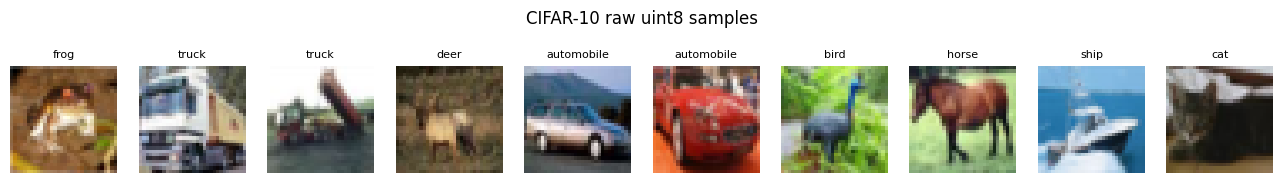

In [2]:
# no transform, so .data stays raw uint8 of shape (N, 32, 32, 3)
cifar_train_raw = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True)
cifar_val_raw   = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
class_names = cifar_train_raw.classes

print(f'train images: {cifar_train_raw.data.shape}, dtype {cifar_train_raw.data.dtype}')
print(f'val   images: {cifar_val_raw.data.shape}')
print(f'classes: {class_names}')

X_train_raw = cifar_train_raw.data[:200]                 # (200, 32, 32, 3) uint8
y_train_raw = np.array(cifar_train_raw.targets[:200])
X_val_raw   = cifar_val_raw.data[:50]
y_val_raw   = np.array(cifar_val_raw.targets[:50])

fig, axes = plt.subplots(1, 10, figsize=(13, 1.7))
for i in range(10):
    axes[i].imshow(X_train_raw[i])
    axes[i].set_title(class_names[y_train_raw[i]], fontsize=8)
    axes[i].axis('off')
plt.suptitle('CIFAR-10 raw uint8 samples', y=1.05)
plt.tight_layout()
plt.show()

- One image = `(32, 32, 3)` → height, width, three colour channels; the grid is kept, nothing is flattened

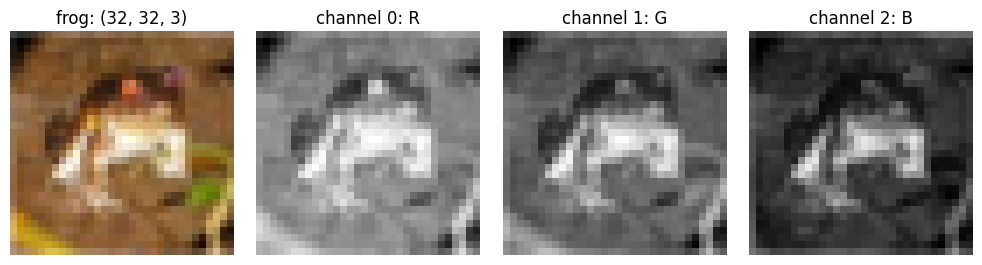

In [3]:
image = X_train_raw[0]                     # (32, 32, 3) uint8

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
axes[0].imshow(image)
axes[0].set_title(f'{class_names[y_train_raw[0]]}: (32, 32, 3)')
for c, name in enumerate(['R', 'G', 'B']):
    axes[c + 1].imshow(image[:, :, c], cmap='gray', vmin=0, vmax=255)
    axes[c + 1].set_title(f'channel {c}: {name}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Same pipeline as tabular data, with two differences:

| | Tabular | Image |
|:---|:---|:---|
| Statistics | `axis=0` → one mean and one std per feature (column) | `axis=(0, 1, 2)` → one mean and one std per channel |
| Layout | `(N, d)` | `(N, C, H, W)` = samples, channels, height, width |

- One mean per channel, the same at every pixel position → a convolution kernel slides over all positions with one set of weights, so all positions must share one scale

Four operations, arrays → batches:

1. `uint8` 0–255 → `float32` 0–1
2. Channel-wise standardization, training statistics only
3. `(N, H, W, C)` → `(N, C, H, W)`
4. `TensorDataset` → `DataLoader`

In [4]:
X_train = X_train_raw.astype(np.float32) / 255.0
X_val   = X_val_raw.astype(np.float32)   / 255.0

# average over the sample and the two spatial axes, leaving one statistic per colour channel
train_mean = X_train.mean(axis=(0, 1, 2))     # (3,)
train_std  = X_train.std(axis=(0, 1, 2))      # (3,)
print(f'train_mean: {train_mean}  shape {train_mean.shape}')
print(f'train_std : {train_std}  shape {train_std.shape}')

X_train = (X_train - train_mean) / train_std
X_val   = (X_val   - train_mean) / train_std  # statistics from the training set

train_mean: [0.48704952 0.47413558 0.4340601 ]  shape (3,)
train_std : [0.24321942 0.23946406 0.25190523]  shape (3,)


In [5]:
X_train_tensor = torch.from_numpy(X_train.transpose(0, 3, 1, 2))
X_val_tensor   = torch.from_numpy(X_val.transpose(0, 3, 1, 2))
y_train_tensor = torch.LongTensor(y_train_raw)
y_val_tensor   = torch.LongTensor(y_val_raw)

train_set = TensorDataset(X_train_tensor, y_train_tensor)
val_set   = TensorDataset(X_val_tensor,   y_val_tensor)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=8, shuffle=False)

X_batch, Y_batch = next(iter(train_loader))
print(f'batch X: {tuple(X_batch.shape)}  (N, C, H, W), dtype {X_batch.dtype}')
print(f'batch Y: {tuple(Y_batch.shape)}')

batch X: (8, 3, 32, 32)  (N, C, H, W), dtype torch.float32
batch Y: (8,)


- A few standardized pixels of the first sample → the reference block to compare with Step 2

In [6]:
print('first sample, channel 0, top-left 4x4 pixels:')
print(X_train_tensor[0, 0, :4, :4].numpy())

first sample, channel 0, top-left 4x4 pixels:
[[-1.0512195  -1.3091967  -1.1963317  -0.90610707]
 [-1.7445335  -2.0025108  -1.7122864  -1.1802081 ]
 [-1.5994213  -1.7445335  -1.2124553  -0.66425335]
 [-1.4704326  -1.3898147  -0.59975904 -0.29341096]]


- Ten lines of NumPy → repeated for every new image dataset
- Tensors fixed in RAM → every epoch sees identical images, so no random crop or flip per epoch (Step 4)

---
## Step 2. A Custom `Dataset` and `transform`

| Method | Returns |
|:---|:---|
| `__init__` | nothing; stores the data and the transform |
| `__len__` | number of samples |
| `__getitem__(index)` | one `(image, label)` pair, transformed |

- `DataLoader` calls `__getitem__` once per sample → that is where the `transform` runs

In [7]:
class CIFAR10Dataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X                   # numpy uint8, (N, 32, 32, 3)
        self.y = y                   # numpy int, (N,)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        image = Image.fromarray(self.X[index])   # numpy array to PIL, the input format transforms expect
        if self.transform is not None:
            image = self.transform(image)
        return image, self.y[index]

- `ToTensor` → operations 1 and 3 of Step 1; `Normalize` → operation 2
- `Normalize(train_mean, train_std)` → the Step 1 statistics: one pair per channel, applied at every pixel position — not one pair per pixel
- `ToTensor` does the division by 255 → the dataset is given the raw `uint8` arrays (`X_train_raw`), not the scaled `X_train`

In [8]:
transform_basic = transforms.Compose([
    transforms.ToTensor(),                              # PIL to (C, H, W) float in [0, 1]
    transforms.Normalize(train_mean, train_std),        # channel-wise, same statistics as Step 1
])

train_set = CIFAR10Dataset(X_train_raw, y_train_raw, transform=transform_basic)
val_set   = CIFAR10Dataset(X_val_raw,   y_val_raw,   transform=transform_basic)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=8, shuffle=False)

X_batch, Y_batch = next(iter(train_loader))
print(f'batch X: {tuple(X_batch.shape)}  (N, C, H, W), dtype {X_batch.dtype}')
print(f'batch Y: {tuple(Y_batch.shape)}')

image0, label0 = train_set[0]              # __getitem__(0): the transformed (C, H, W) tensor and its label
print()
print('first sample, channel 0, top-left 4x4 pixels:')
print(image0[0, :4, :4].numpy())
print('(manual, Step 1)')
print(X_train_tensor[0, 0, :4, :4].numpy())

batch X: (8, 3, 32, 32)  (N, C, H, W), dtype torch.float32
batch Y: (8,)

first sample, channel 0, top-left 4x4 pixels:
[[-1.0512195  -1.3091967  -1.1963317  -0.90610707]
 [-1.7445335  -2.0025108  -1.7122864  -1.1802081 ]
 [-1.5994213  -1.7445335  -1.2124553  -0.66425335]
 [-1.4704326  -1.3898147  -0.59975904 -0.29341096]]
(manual, Step 1)
[[-1.0512195  -1.3091967  -1.1963317  -0.90610707]
 [-1.7445335  -2.0025108  -1.7122864  -1.1802081 ]
 [-1.5994213  -1.7445335  -1.2124553  -0.66425335]
 [-1.4704326  -1.3898147  -0.59975904 -0.29341096]]


- Same 4×4 block → two transforms replace the ten lines of NumPy
- From here on only `__getitem__` changes → its source, or its transform

- Standardized pixels can be negative → undo the scaling before `imshow`

In [9]:
# turns a standardized (C, H, W) tensor back into an (H, W, C) array that imshow can display
def unnormalize(image_tensor):
    image = image_tensor.permute(1, 2, 0).numpy()
    image = image * train_std + train_mean
    return np.clip(image, 0, 1)

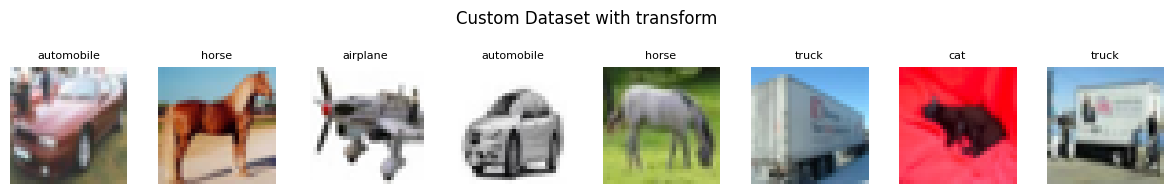

In [10]:
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for i in range(8):
    axes[i].imshow(unnormalize(X_batch[i]))
    axes[i].set_title(class_names[Y_batch[i]], fontsize=8)
    axes[i].axis('off')
plt.suptitle('Custom Dataset with transform', y=1.05)
plt.tight_layout()
plt.show()

---
## Step 3. Reading from Disk — `ImageFolder` and Built-in Datasets

- All images in RAM → fails at a few hundred thousand photographs
- `__getitem__` reads a file instead → only the current batch is in memory

| Class | Data lives in | RAM held |
|:---|:---|:---|
| `TensorDataset` | RAM tensor | the whole dataset |
| `CIFAR10Dataset` | RAM array | the whole dataset |
| `ImageFolder` | files on disk | one batch |

### 3.1 `ImageFolder`

- `ImageFolder(root, transform)` → subfolder names are the class labels

```
ROOT/
├── train/  plane/  car/  bird/  cat/  deer/
└── test/   plane/  car/  bird/  cat/  deer/
```

- Your own photographs work the same way in this layout
- The archive below → 5 classes, 100 train / 50 test images each

In [11]:
ROOT = './data/cifar5_imagefolder'
URL  = 'https://raw.githubusercontent.com/jongmoonha/AI-ME-Practice/main/data/cifar5_imagefolder.zip'

if not os.path.exists(ROOT):
    os.makedirs('./data', exist_ok=True)
    print('downloading cifar5_imagefolder (about 2 MB) ...')
    downloaded_archive = './data/cifar5_imagefolder_download.zip'
    urllib.request.urlretrieve(URL, downloaded_archive)
    with zipfile.ZipFile(downloaded_archive) as archive:
        archive.extractall('./data/')
    os.remove(downloaded_archive)
    print('done.')

for split in ['train', 'test']:
    print(split)
    for name in sorted(os.listdir(f'{ROOT}/{split}')):
        count = len(os.listdir(f'{ROOT}/{split}/{name}'))
        print(f'  {name}: {count} images')

train
  bird: 100 images
  car: 100 images
  cat: 100 images
  deer: 100 images
  plane: 100 images
test
  bird: 50 images
  car: 50 images
  cat: 50 images
  deer: 50 images
  plane: 50 images


samples       : 500
classes       : ['bird', 'car', 'cat', 'deer', 'plane']
class to index: {'bird': 0, 'car': 1, 'cat': 2, 'deer': 3, 'plane': 4}


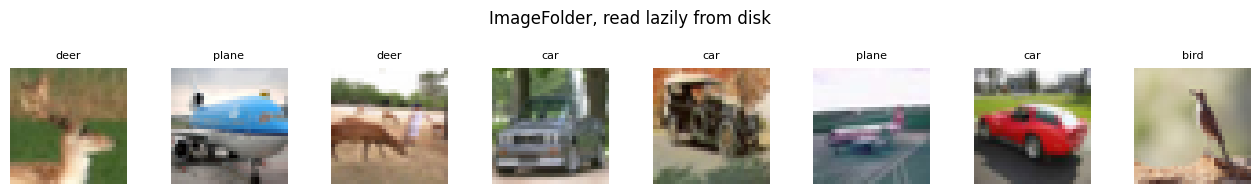

In [12]:
# same transform as Step 2; only the source of the images changed
imagefolder_train = torchvision.datasets.ImageFolder(root=f'{ROOT}/train', transform=transform_basic)

print(f'samples       : {len(imagefolder_train)}')
print(f'classes       : {imagefolder_train.classes}')
print(f'class to index: {imagefolder_train.class_to_idx}')

imagefolder_loader = DataLoader(imagefolder_train, batch_size=8, shuffle=True)
X_batch, Y_batch = next(iter(imagefolder_loader))

fig, axes = plt.subplots(1, 8, figsize=(13, 1.8))
for i in range(8):
    axes[i].imshow(unnormalize(X_batch[i]))
    axes[i].set_title(imagefolder_train.classes[Y_batch[i]], fontsize=8)
    axes[i].axis('off')
plt.suptitle('ImageFolder, read lazily from disk', y=1.05)
plt.tight_layout()
plt.show()

- Class index = alphabetical folder order (bird 0 … plane 4) → not the CIFAR-10 numbering

### 3.2 Built-in Datasets

- `datasets.CIFAR10`, `datasets.MNIST`, ... → same `transform` argument, no class to write
- `datasets.CIFAR10` keeps its images in RAM (`.data` in Step 1) → unlike `ImageFolder`, nothing is read per call
- Published channel statistics, from all 50000 training images → close to the 200-image values (red: 0.491 vs. 0.487); Steps 4–5 keep the Step 1 statistics

In [13]:
# published CIFAR-10 statistics, one pair per channel over all pixels of the 50000 training images
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

cifar_train = torchvision.datasets.CIFAR10(
    root='./data', train=True,  download=True, transform=transform_cifar)
cifar_val = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_cifar)

cifar_loader = DataLoader(cifar_train, batch_size=8, shuffle=True)
X_batch, Y_batch = next(iter(cifar_loader))

print(f'train: {len(cifar_train)} samples, val: {len(cifar_val)} samples')
print(f'batch X: {tuple(X_batch.shape)}, batch Y: {tuple(Y_batch.shape)}')

train: 50000 samples, val: 10000 samples
batch X: (8, 3, 32, 32), batch Y: (8,)


---
## Step 4. Augmentation — A New View Every Call

- `ToTensor`, `Normalize` are deterministic → same index, same tensor
- Random transforms → a new view of each image every epoch, which reduces overfitting
- Training only → evaluation has to be deterministic

| Transform | Effect |
|:---|:---|
| `RandomCrop(32, padding=4)` | zero-pads, then cuts a 32×32 window at a random offset |
| `RandomHorizontalFlip(p=0.5)` | mirrors left to right half the time |

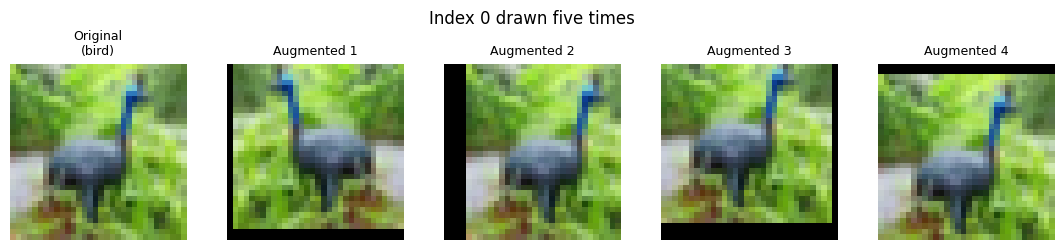

In [14]:
transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(train_mean, train_std),
])

# same files, same Dataset class as Step 3, only the transform differs
imagefolder_train_aug = torchvision.datasets.ImageFolder(root=f'{ROOT}/train', transform=transform_aug)

torch.manual_seed(42)                                    # the random crop and flip draw from this state
image_plain, label_plain = imagefolder_train[0]          # deterministic transform

fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
axes[0].imshow(unnormalize(image_plain))
axes[0].set_title(f'Original\n({imagefolder_train.classes[label_plain]})', fontsize=9)
axes[0].axis('off')
for k in range(1, 5):
    image_aug, _ = imagefolder_train_aug[0]              # index 0 again, a new random view each time
    axes[k].imshow(unnormalize(image_aug))
    axes[k].set_title(f'Augmented {k}', fontsize=9)
    axes[k].axis('off')
plt.suptitle('Index 0 drawn five times')
plt.tight_layout()
plt.show()

- A `DataLoader` fills its batches through the same `__getitem__` → its batches are augmented too
- `shuffle=False` → two `next(iter(...))` calls return the same 8 images, so only the augmentation differs

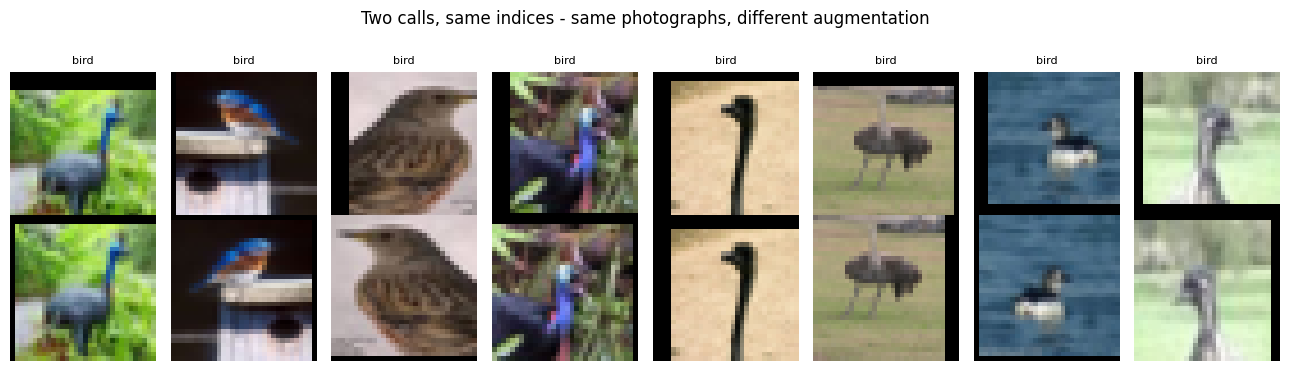

In [15]:
train_loader_aug = DataLoader(imagefolder_train_aug, batch_size=8, shuffle=False)

X_batch1, Y_batch1 = next(iter(train_loader_aug))
X_batch2, Y_batch2 = next(iter(train_loader_aug))

fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for i in range(8):
    axes[0, i].imshow(unnormalize(X_batch1[i]))
    axes[0, i].set_title(imagefolder_train.classes[Y_batch1[i]], fontsize=8)
    axes[0, i].axis('off')
    axes[1, i].imshow(unnormalize(X_batch2[i]))
    axes[1, i].axis('off')
plt.suptitle('Two calls, same indices - same photographs, different augmentation', y=1.02)
plt.tight_layout()
plt.show()

---
## Step 5. The Pair of Loaders a Training Run Needs

- Training and evaluation differ in the transform, not in the dataset class

| Split | Transform | Shuffle |
|:---|:---|:---|
| train | random crop, flip, `ToTensor`, `Normalize` | yes |
| val, test | `ToTensor`, `Normalize` | no |

In [16]:
train_set_final = torchvision.datasets.ImageFolder(root=f'{ROOT}/train', transform=transform_aug)
val_set_final   = torchvision.datasets.ImageFolder(root=f'{ROOT}/test',  transform=transform_basic)

train_loader_final = DataLoader(train_set_final, batch_size=8, shuffle=True)
val_loader_final   = DataLoader(val_set_final,   batch_size=8, shuffle=False)

X_batch, Y_batch = next(iter(train_loader_final))
print(f'train batch: {tuple(X_batch.shape)}, augmented')
X_batch, Y_batch = next(iter(val_loader_final))
print(f'val   batch: {tuple(X_batch.shape)}, not augmented')

train batch: (8, 3, 32, 32), augmented
val   batch: (8, 3, 32, 32), not augmented


---
## Summary

- A `Dataset` = `__len__` + `__getitem__` → the classes here differ only in what `__getitem__` reads
- `ToTensor` + `Normalize` → replace the hand-written scaling, standardization and transpose; one mean and one std per channel
- Random transforms → a new view per epoch at no storage cost; keep them off the evaluation loaders

---
## Exercises

1. `train_mean`, `train_std` over all 50000 images — how far from the 200-image values?
2. Give `val_loader_final` the augmented transform and draw one batch twice — why would validation accuracy become hard to read?
3. Add `transforms.RandomRotation(15)` to `transform_aug` — redraw index 0 four times.
4. Point `ImageFolder` at your own photographs, one subfolder per class — draw a batch.

In [17]:
# Write your code here